# ML Pipeline Formative 1: Task 1 - EDA
## Part A: Understanding The Dataset

Author: Patrick Tuyizere

The `Metro Interstate Traffic Volume` dataset from kaggle contains hourly traffic volume for the interstate 94 westbound at Minneapolis, St-Paul, Minnesota together with local weather conditions.

- **Time Rage**: The dataset begins on October 2, 2012 at 09:00:00 and concludes on September 30, 2018 at 23:00:00 (accounting for approximately 6 years of observations).
- **Frequency**: The dataset contains 48,204 rows recorded an an hourly frequency. Analysing the timestamps reveals that due to sensor mulfunctions, there are non continous time gaps that exist in the dataset.
- **Target Variable**: `traffic_volume` This a a continous integer that that measures the number of vehicles passing the sensor in an hour.

In [8]:
# connect to drive
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib

# 1. Load dataset and parse datetime
df = pd.read_csv("/content/drive/MyDrive/ml_pipeline_formative1_dataset/Metro_Interstate_Traffic_Volume.csv")
df["date_time"] = pd.to_datetime(df["date_time"])
df = df.sort_values("date_time").reset_index(drop=True)

# 2. Inspect time range and basic info
print(f"Start Date: {df['date_time'].min()}")
print(f"End Date:   {df['date_time'].max()}")
print(f"Total Rows: {len(df)}")

Start Date: 2012-10-02 09:00:00
End Date:   2018-09-30 23:00:00
Total Rows: 48204


### Missing Values, Gaps, and Outlier Handling

When we run `df.isnull().sum()`, we see that there are no missing values in the raw CSV. Pandas simply treats the "None" string found in the holiday column as a missing value indicator but that doesn't mean that the values are missing. We handle this quirk later. Time series data has 2 data quality issues that require handling:
1. **Duplicate Timestamps**: Multiple weather descriptions recorded in the same hour (e.g: both "Rain" and "Mist") produce duplicate hourly timestamps.
2. **Missing Hourly Time Intervals**: Given a time period spanning 6 years from 2012 to 2018. There should be around 52,560 hourly intervals but there is only around 48,204.
3. **Sensor Outliers**: The `temp` column contains values recorded as 0.0 Kelvin ($-273.15 C), which is physically impossible and indicates sensor failure. Also `rain_1h` contains spikes exceeding 9,000 mm.

### Preprocessing Strategy
- **Removing duplicates**: We put together multiple readings per hour by taking the mean of numerical variables and the most severe of categorical weather.
- **Fixing the indexes**: We also reindex the dataset into a complete, uninterrupted hourly format.
- **Imputation**: Missing temperature and weather features are imputed using linear interpolation (`df.interpolate(method='time')`). The Target variable `traffic_volume` missing values are also imputed using forward-fill (`ffill`) followed by backward-fill (`bfill`), or historical median by hour-of-week and sensor anomalies (`temp == 0 or rain_1h > 500`) are flagged as NaN before interpolation.

In [10]:
# 1. False missing values in 'holiday'
print("-----Issue 1 - Null Check And Holiday Inspection:-----")
print(df.isnull().sum())
print("Unique vals in 'holiday':")
print(df["holiday"].value_counts(dropna=False).head(5))

# Handling the missing values in 'holiday'
df["holiday"] = df["holiday"].fillna("None")
df["is_holiday"] = (df["holiday"] != "None").astype(int)

# 2. Duplicate timestamps
print("\n-----Issue 2 - Duplicate Timestamps:-----")
print(f"Number of duplicate timestamp rows: {df.duplicated(["date_time"]).sum()}")

# Fix duplicate timestamps
df_hourly = df.groupby("date_time").mean(numeric_only=True).reset_index()

# 3. Missing hourly intervals
print("\n-----Issue 3 - Missing Hourly Intervals:-----")
time_diffs = df["date_time"].drop_duplicates().diff()
print("Top longest time gaps between consecutive measurements:")
print(time_diffs.value_counts().head(5))
expected_hours = (pd.date_range(start=df["date_time"].min(), end=df["date_time"].max(), freq="h").shape[0])
actual_unique_hours = df["date_time"].nunique()
print(f"Expected hourly slots: {expected_hours}")
print(f"Actual unique slots:   {actual_unique_hours}")
print(f"Missing hourly slots:  {expected_hours - actual_unique_hours}")

# Fix missing intervals
df_hourly = df_hourly.set_index("date_time")
full_timeline = pd.date_range(start=df_hourly.index.min(), end=df_hourly.index.max(), freq="h")
df_clean = df_hourly.reindex(full_timeline)
df_clean.index.name = "date_time"

# 4. Sensor mulfunctions
print("\n-----Issue 4 - Sensor Mulfunctions:-----")
temp_outliers = df[df["temp"] < 100]
rain_outliers = df[df["rain_1h"] > 500]
print(f"Rows with impossible temperatures: {len(temp_outliers)}")
print(temp_outliers[["date_time", "temp", "traffic_volume"]].head(3))
print(f"Rows with impossible rainfall: {len(rain_outliers)}")
print(rain_outliers[["date_time", "rain_1h", "traffic_volume"]])

# Fix sensor mulfunctions
df.loc[df["temp"] < 100, "temp"] = np.nan
df.loc[df["rain_1h"] > 500, "rain_1h"] = np.nan

# 5. Impute continuous and discrete values
df_clean["temp"] = df_clean["temp"].interpolate(method="time")
df_clean["clouds_all"] = df_clean["clouds_all"].interpolate(method="time")

df_clean["rain_1h"] = df_clean["rain_1h"].fillna(0.0)
df_clean["snow_1h"] = df_clean["snow_1h"].fillna(0.0)

df_clean["traffic_volume"] = df_clean["traffic_volume"].ffill().bfill()
df_clean["is_holiday"] = df_clean["is_holiday"].fillna(0).astype(int)

print(f"Final Cleaned Dataset Shape: {df_clean.shape}")
print(f"Remaining Missing Values:\n{df_clean.isnull().sum()}")

-----Issue 1 - Null Check And Holiday Inspection:-----
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
dtype: int64
Unique vals in 'holiday':
holiday
NaN                          48143
Labor Day                        7
Christmas Day                    6
Thanksgiving Day                 6
Martin Luther King Jr Day        6
Name: count, dtype: int64

-----Issue 2 - Duplicate Timestamps:-----
Number of duplicate timestamp rows: 7629

-----Issue 3 - Missing Hourly Intervals:-----
Top longest time gaps between consecutive measurements:
date_time
0 days 01:00:00    37986
0 days 02:00:00     2192
0 days 03:00:00      201
0 days 04:00:00       59
0 days 05:00:00       33
Name: count, dtype: int64
Expected hourly slots: 52551
Actual unique slots:   40575
Missing hourly slots:  11976



In [14]:
summary_stats = df_clean.describe().round(2)
print(summary_stats)
df_clean.head()

           temp   rain_1h   snow_1h  clouds_all  traffic_volume  is_holiday
count  52551.00  52551.00  52551.00    52551.00        52551.00    52551.00
mean     282.50      0.25      0.00       44.52         2900.77        0.00
std       12.99     42.89      0.00       36.93         2083.16        0.03
min        0.00      0.00      0.00        0.00            0.00        0.00
25%      273.58      0.00      0.00        1.00          551.00        0.00
50%      286.42      0.00      0.00       40.00         2883.00        0.00
75%      291.70      0.00      0.00       89.00         4790.00        0.00
max      310.07   9831.30      0.51      100.00         7280.00        1.00


,temp,rain_1h,snow_1h,clouds_all,traffic_volume,is_holiday
date_time,,,,,,
2012-10-02 09:00:00,288.28,0.0,0.0,40.0,5545.0,0
2012-10-02 10:00:00,289.36,0.0,0.0,75.0,4516.0,0
2012-10-02 11:00:00,289.58,0.0,0.0,90.0,4767.0,0
2012-10-02 12:00:00,290.13,0.0,0.0,90.0,5026.0,0
2012-10-02 13:00:00,291.14,0.0,0.0,75.0,4918.0,0


## Part B: Analytical Questions

In [15]:
# Feature engineering for analytical questions
# Lagged values: 1 hour ago, 24 hours ago (yesterday same hour), 168 hours ago (last week same hour)
df_clean["lag_1"] = df_clean["traffic_volume"].shift(1)
df_clean["lag_24"] = df_clean["traffic_volume"].shift(24)
df_clean["lag_168"] = df_clean["traffic_volume"].shift(168)

# Moving averages: 24-hour rolling mean and 7-day (168-hour) rolling mean
df_clean["rolling_mean_24"] = (
    df_clean["traffic_volume"].rolling(window=24).mean()
)
df_clean["rolling_mean_168"] = (
    df_clean["traffic_volume"].rolling(window=168).mean()
)

# Extract calendar helpers
df_clean["hour"] = df_clean.index.hour
df_clean["dayofweek"] = df_clean.index.dayofweek
df_clean["is_weekend"] = df_clean["dayofweek"].isin([5, 6]).astype(int)

### Question 1: Does traffic volume have an increasing or decreasing trend over time, and how does a moving average make it easier to see?

On an hourly basis, the traffic volume jumps up and down making it particularly difficult to see long term trends.

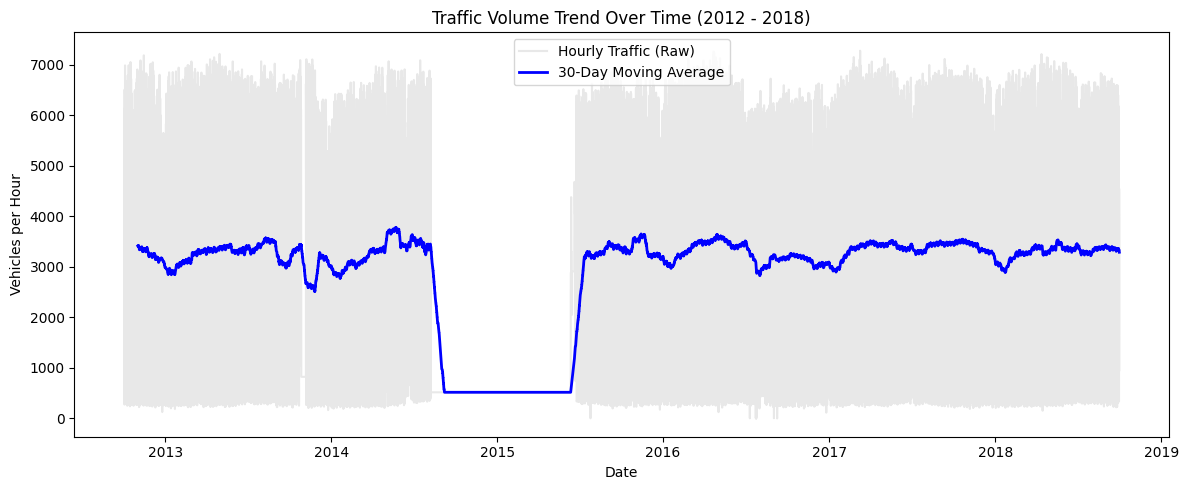

In [18]:
# 1. Calculate a 30-day (720 hours) moving average
df_clean["traffic_30d_ma"] = (df_clean["traffic_volume"].rolling(window=720).mean())

# 2. Plot raw traffic alongside the moving average
plt.figure(figsize=(12, 5))
plt.plot(
    df_clean.index,
    df_clean["traffic_volume"],
    color="lightgray",
    alpha=0.5,
    label="Hourly Traffic (Raw)",
)
plt.plot(
    df_clean.index,
    df_clean["traffic_30d_ma"],
    color="blue",
    linewidth=2,
    label="30-Day Moving Average",
)
plt.title("Traffic Volume Trend Over Time (2012 - 2018)")
plt.xlabel("Date")
plt.ylabel("Vehicles per Hour")
plt.legend()
plt.tight_layout()
plt.show()

The resulting plot shows long term stable, flat trend consistently averaging between 3000 - 3,500 vehicles per hour. The huge deep drop from late 2014 to mid 2015 suggests a major sensor outage and mulfunctions. The blue line shows the 30 day moving average and behid is the gray band showing the day and night spikes. We can also see a fairly consistent drop in traffic volume towards the end of each year most likely cuased by winter cold temperatures.

### Question 2: Are there lag effects where traffic volume right now is related to traffic volume from previous hours?
Usually in time series data, the current value depends on the past values.
I create 2 lag features:
1. **Lag 1**: Traffic 1 hour ago(`shift(1)`)
2. **Lag 24**: Traffic at the exact same hour yesterday (`shift(24)`)

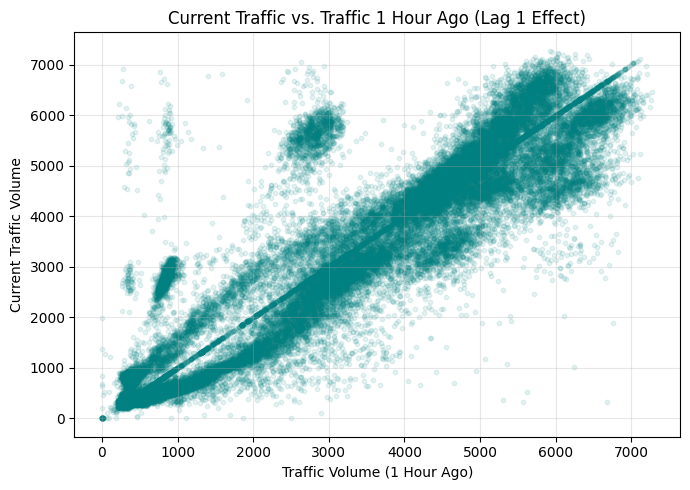

Correlation with 1 hour ago:  0.93
Correlation with 24 hours ago: 0.86


In [19]:
# 1. Create lag features
df_clean["lag_1"] = df_clean["traffic_volume"].shift(1)
df_clean["lag_24"] = df_clean["traffic_volume"].shift(24)

# 2. Scatter plot the current traffic vs traffic 1 hour ago
plt.figure(figsize=(7, 5))
plt.scatter(
    df_clean["lag_1"],
    df_clean["traffic_volume"],
    alpha=0.1,
    color="teal",
    s=10,
)
plt.title("Current Traffic vs. Traffic 1 Hour Ago (Lag 1 Effect)")
plt.xlabel("Traffic Volume (1 Hour Ago)")
plt.ylabel("Current Traffic Volume")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Print correlation values
print(f"Correlation with 1 hour ago:  {df_clean['traffic_volume'].corr(df_clean['lag_1']):.2f}")
print(f"Correlation with 24 hours ago: {df_clean['traffic_volume'].corr(df_clean['lag_24']):.2f}")

The scatter plotting shows a strong correlation between consecutive hours. This means that traffic doesn't jump or fall dramatically from one hour to another. The data concentrates in 2 critical zones. A lower cluster of 500 - 1,000 vehicles (late night and early morning) and a higher cluster of 4,500 - 6,000 vehicles (daytime traffic and rush hours). A key observation is that lag 1 could serve as the perfect baseline so including it as an input feature in any predictive model would allow for good future hour predictions.

### Question 3: Do external weather variables correlate with traffic volume over time?
A common assumption is that bad weather results in reduced traffic volume. We then evaluate correlation between traffic volume and weather variables.

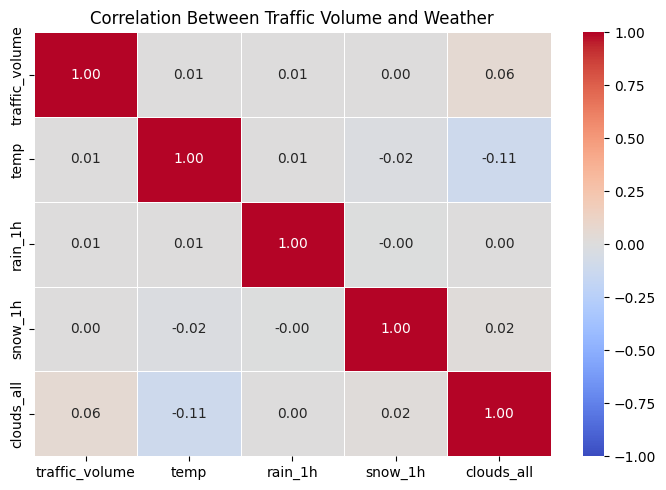

In [25]:
# 1. Select traffic and weather columns
weather_cols = ["traffic_volume", "temp", "rain_1h", "snow_1h", "clouds_all"]
corr_matrix = df_clean[weather_cols].corr()

# 2. Plot correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
)
plt.title("Correlation Between Traffic Volume and Weather")
plt.tight_layout()
plt.show()

The heatmap shows virtually no linear correlation between all weather variables and traffic volume. This is an apparent contradiction with our conclusion that cold winter periods result in a drop in traffic year on year. The reason is because the 24 hourly circle in the dataset introduces hourly noise that masks seasonal trends.

### Question 4: What hours of the day have the highest and lowest traffic volume?
If we calculate the average traffic for every hour of the day (from 0 to 23), we can spot the exact commute peaks.

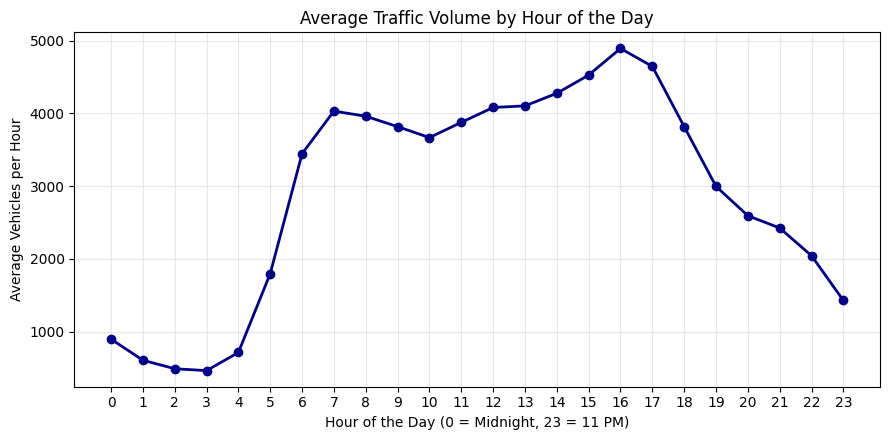

In [26]:
# 1. Group by hour of the day and calculate average traffic
hourly_traffic = df_clean.groupby(df_clean.index.hour)["traffic_volume"].mean()

# 2. Plot hourly line chart
plt.figure(figsize=(9, 4.5))
plt.plot(
    hourly_traffic.index,
    hourly_traffic.values,
    marker="o",
    color="darkblue",
    linewidth=2,
)
plt.title("Average Traffic Volume by Hour of the Day")
plt.xlabel("Hour of the Day (0 = Midnight, 23 = 11 PM)")
plt.ylabel("Average Vehicles per Hour")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The graph shows the typical distribution of traffic volume due to commuting trips throughout the day, the low point of traffic volume occurs between 2:00 AM and 3:00 AM (below 500 vehicles/hour), and there is a sharp increase in traffic volume during morning rush hour until the traffic reaches its first peak of about 4,000 vehicles/hour at 7:00 AM. Maintaining the high volume up until midday, traffic peaks for the second time at 4:00 PM (Hour 16) at a high point of nearly 4,900 vehicles/hour due to the evening commute trip.

### Question 5: How does traffic volume differ between weekdays and weekends?

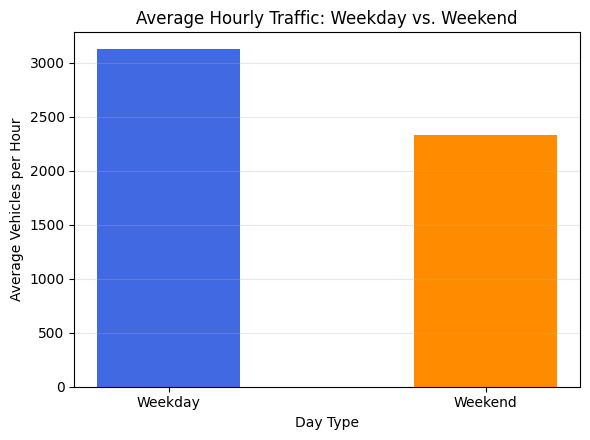

date_time
Weekday    3126.951715
Weekend    2335.817692
Name: traffic_volume, dtype: float64


In [27]:
# 1. Create label: Weekday vs Weekend (5 and 6 are Saturday and Sunday)
day_label = df_clean.index.dayofweek.map(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)
weekday_comparison = df_clean.groupby(day_label)["traffic_volume"].mean()

# 2. Bar plot comparing the two averages
plt.figure(figsize=(6, 4.5))
plt.bar(
    weekday_comparison.index,
    weekday_comparison.values,
    color=["royalblue", "darkorange"],
    width=0.45,
)
plt.title("Average Hourly Traffic: Weekday vs. Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Vehicles per Hour")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(weekday_comparison)

It can be seen that there is a notable increase in the number of cars on weekdays when compared to the weekends. On average, weekdays register over 3,100 cars per hour, while the number drops down to about 2,350 cars per hour during the weekends. This is due to the fact that people travel to work and schools from Monday to Friday, and as a result fewer journeys during the weekend days.

## Part C: Model Training And Experiment Comparison
To predict `traffic_volume`, we chose to use a Random Forest Regressor which should be able to adequately capture non linear interactions and require less feature normalization.

### 1. Train, Test Split
In time-series dataset due to data leakage, we split chronologically:
- **Training Set**: Data before Jan 2018 (around 88%)
- **Test Set**: Data after Jan 2018

In [29]:
# 1. Prepare feature matrix and drop rows with lag NaNs
feature_cols_basic = ["hour", "dayofweek", "temp", "clouds_all", "rain_1h"]
feature_cols_advanced = [
    "hour",
    "dayofweek",
    "is_weekend",
    "temp",
    "clouds_all",
    "rain_1h",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
]

model_data = df_clean.dropna().copy()

# 2. Chronological Train-Test Split (Cutoff: Jan 1, 2018)
train_df = model_data.loc[model_data.index < "2018-01-01"]
test_df = model_data.loc[model_data.index >= "2018-01-01"]

y_train = train_df["traffic_volume"]
y_test = test_df["traffic_volume"]

### 2. Model Experiments And Hyperparameter Tuning
- **Experiment 1 - Baseline**: Uses basic calendar and weather features (`hour`, `dayofweek`, `temp`, `clouds_all`, `rain_1h`) without lag signals. Trees are constrained to shallow depth (`n_estimators=50`, `max_depth=8`) to prevent overfitting.
- **Experiment 2 - Tuned Autoregressive**: Uses full time series context (`lag_1`, `lag_24`, `lag_168`, `rolling_mean_24`) with deeper tree capacity (`n_estimators=100`, `max_depth=18`, `min_samples_leaf=4`).

In [31]:
# Experiment 1: Baseline Shallow Forest (No Lags)
X_train_exp1 = train_df[feature_cols_basic]
X_test_exp1 = test_df[feature_cols_basic]

exp1_model = RandomForestRegressor(
    n_estimators=50, max_depth=8, random_state=42, n_jobs=-1
)
exp1_model.fit(X_train_exp1, y_train)
y_pred_exp1 = exp1_model.predict(X_test_exp1)

# Experiment 2: Tuned Deep Forest with Lags and Rolling Averages
X_train_exp2 = train_df[feature_cols_advanced]
X_test_exp2 = test_df[feature_cols_advanced]

exp2_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=18,
    min_samples_leaf=4,
    random_state=42,
    n_jobs=-1,
)
exp2_model.fit(X_train_exp2, y_train)
y_pred_exp2 = exp2_model.predict(X_test_exp2)


# Function to calculate performance metrics
def get_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return round(mae, 2), round(rmse, 2), round(r2, 4)


mae_1, rmse_1, r2_1 = get_metrics(y_test, y_pred_exp1)
mae_2, rmse_2, r2_2 = get_metrics(y_test, y_pred_exp2)

# Print results
comparison_df = pd.DataFrame(
    {
        "Metric": [
            "MAE (Vehicles)",
            "RMSE (Vehicles)",
            "R² Score",
        ],
        "Experiment 1 (Baseline)": [mae_1, rmse_1, r2_1],
        "Experiment 2 (Tuned + Lags)": [mae_2, rmse_2, r2_2],
    }
)

print("\nComparison Summary Table:")
print(comparison_df.to_string(index=False))


Comparison Summary Table:
         Metric  Experiment 1 (Baseline)  Experiment 2 (Tuned + Lags)
 MAE (Vehicles)                 438.4800                     154.9800
RMSE (Vehicles)                 804.3600                     238.3600
       R² Score                   0.8344                       0.9855


In Experiment 2, the model clearly beats the baseline in all respects, proving that historical traffic is much more important than weather and date-time information. While the baseline managed to capture the basic daily cycle of traffic (R² Score=0.8344) quite well, by introducing the lag and rolling averages we were able to reduce the mean absolute error from about 438 vehicles per hour to 155. What is especially impressive, however, is the decrease in RMSE from 804 to 238, which implies that the tuned model does not miss by a long shot during the critical period of transition and explains over 98% of the total variance in traffic (R² Score=0.9855).

### 3. Save The Best Model

In [33]:
joblib.dump(exp2_model, "traffic_forecasting_model.pkl")
print("Model successfully saved!")

Model successfully saved!


### 4. Save Processed Data

In [34]:
# 1. Reset index so 'date_time' becomes an explicit column
export_df = df_clean.reset_index()

# 2. Save the fully cleaned data
export_df.to_csv("metro_traffic_clean.csv", index=False)

print(f"Successfully added {len(export_df)} rows to 'metro_traffic_clean.csv'!")


Successfully added 52551 rows to 'metro_traffic_clean.csv'!
